## Model 2 revisited: the duration grid limits which gaps greedy DBQA resolves

`Example_5` ran stage 1 on the full Er$^{3+}$:LiYF$_4$ Hamiltonian (units of 20 000 cm$^{-1}$) with durations $s \in [10^{-4}, 10]$. Its group-commutator run isolated the free-ion multiplets but left the crystal-field levels of $^4I_{15/2}$ 55–76 cm$^{-1}$ off after 150 iterations. `RESULTS_Model_2.md` attributed this to the greedy objective being dominated by the large free-ion couplings.

Model 3 (`Example_9`) showed a simpler cause. In the rescaled units a coupling across a gap $g$ is removed by a group-commutator step only if the duration reaches about $1/g$. The crystal-field gaps of $^4I_{15/2}$ are 0.36–203 cm$^{-1}$, i.e. $1.8\times10^{-5}$–$10^{-2}$ in units of 20 000 cm$^{-1}$, and the same-irrep gap that turned out to be the slowest mode (5.98 cm$^{-1}$) is $3\times10^{-4}$. Durations up to 10 cannot resolve it.

This notebook repeats the group-commutator stage 1 of `Example_5` with durations $s \in [10^{-4}, 10^4]$ (160 log-spaced values; 150 iterations, about an hour), and compares with the saved $s \le 10$ run.

In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "4"

import logging
import pickle
import time

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))
set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)

with open("simulation_results/Er_LiYF4_DBQA_L_9.pickle", "rb") as file:
    saved = pickle.load(file)
energy_unit, doublets, manifolds = saved["energy_unit"], saved["doublets"], saved["manifolds"]
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff = er_liyf4_pycf_coeff(ER_LIYF4_FREE_ION_REFIT)
h, _ = crystal_field_hamiltonian([getattr(f11cf, name) for name in coeff], coeff, energy_unit=energy_unit)
matrix = h.backend.to_numpy(h.matrix)
assert np.allclose(np.linalg.eigvalsh(matrix), saved["energies"])

[Qibo 0.2.14|INFO|2026-10-17 06:40:14]: Using numpy backend on /CPU:0


In [2]:
start = time.time()
run = run_dbqa_history(matrix, "group commutator", dict(doublets=doublets, manifolds=manifolds), 150, np.logspace(-4, 4, 160))
print(f"{(time.time() - start) / 60:.0f} min")


def ground_multiplet(history):
    error = np.array([np.max(r["doublets"]["level_energy_error"][:8]) for r in history]) * energy_unit
    infidelity = np.array([np.max(1 - r["doublets"]["level_fidelity"][:8]) for r in history])
    manifold = np.array([1 - r["manifolds"]["level_fidelity"][0] for r in history])
    return error, infidelity, manifold


old = ground_multiplet(saved["stage1"]["group commutator"]["history"])
new = ground_multiplet(run["history"])
print(f"{'':28s} {'k=25':>9s} {'k=50':>9s} {'k=100':>9s} {'k=150':>9s}")
for label, (error, infidelity, manifold) in [("s <= 10 (Example 5)", old), ("s <= 1e4", new)]:
    print(f"{label:20s} max|dE| " + " ".join(f"{error[k]:9.3f}" for k in (25, 50, 100, 150)) + "  cm^-1")
    print(f"{'':20s} max 1-F " + " ".join(f"{infidelity[k]:9.1e}" for k in (25, 50, 100, 150)))
    print(f"{'':20s} 1-F(4I15/2 manifold) " + " ".join(f"{manifold[k]:9.1e}" for k in (25, 50, 100, 150)))
steps = np.array(run["steps"])
print(f"durations chosen with s <= 1e4: median {np.median(steps):.2g}, max {steps.max():.2g}; {np.sum(steps > 10)} of 150 steps above 10")

/home/aarush_das_bansiwal/micromamba/envs/dbqa-cf/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


47 min
                                  k=25      k=50     k=100     k=150
s <= 10 (Example 5)  max|dE|   116.794   115.354    98.222    75.884  cm^-1
                     max 1-F   1.0e+00   1.0e+00   1.0e+00   1.0e+00
                     1-F(4I15/2 manifold)   1.0e-06   1.2e-09   1.4e-09   3.1e-10
s <= 1e4             max|dE|   116.857    37.366    11.320     0.187  cm^-1
                     max 1-F   1.0e+00   1.0e+00   1.0e+00   3.1e-02
                     1-F(4I15/2 manifold)   7.8e-08   3.2e-09   3.7e-09   8.5e-11
durations chosen with s <= 1e4: median 1.7, max 2e+03; 40 of 150 steps above 10


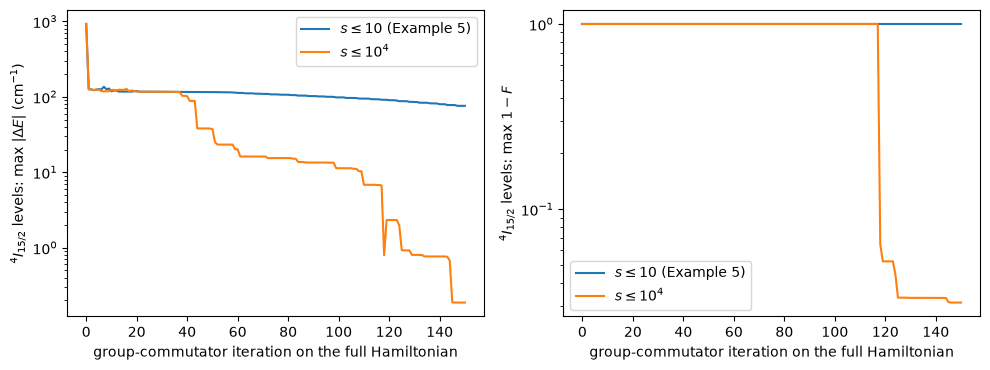

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (error, infidelity, _), label in [(old, r"$s \leq 10$ (Example 5)"), (new, r"$s \leq 10^4$")]:
    axes[0].plot(error, label=label)
    axes[1].plot(infidelity, label=label)
axes[0].set_ylabel(r"$^4I_{15/2}$ levels: max $|\Delta E|$ (cm$^{-1}$)")
axes[1].set_ylabel(r"$^4I_{15/2}$ levels: max $1-F$")
for ax in axes:
    ax.set_yscale("log"); ax.set_xlabel("group-commutator iteration on the full Hamiltonian"); ax.legend()
plt.tight_layout()
plt.savefig("pdfs_figures/Er_LiYF4_step_range.pdf")
plt.show()
with open("simulation_results/Er_LiYF4_step_range_L_9.pickle", "wb") as file:
    pickle.dump(dict(space=np.logspace(-4, 4, 160), history=run["history"], steps=run["steps"]), file)

**Result.** With durations up to $10^4$ the same greedy group-commutator stage 1 brings every $^4I_{15/2}$ level within 0.19 cm$^{-1}$ in 150 iterations, against 76 cm$^{-1}$ with $s \le 10$; 40 of the 150 chosen durations exceed 10. The residual 3 % infidelity sits on levels 0 and 2 (0 and 5.98 cm$^{-1}$), the same-irrep coupling that is also the slowest mode of the two-stage strategy. Greedy DBQA therefore does resolve the crystal-field scale when the grid allows it; the two-stage strategy of `Example_5` remains faster (0.075 cm$^{-1}$ after 16 + 45 iterations). `RESULTS_Model_2.md` §8 records this correction.